# 📗 Pre-Workshop Notebook 2: Working with Larger Research Datasets
## Scientific Workflows for Brain and Behavioral Research
### National Science Foundation Supported Learning Initiative (Award No. OAC-2417875)

---

## 📋 Set Up Your Profile
*Run the cell below to record your progress.*

In [1]:
# PROFILE SYNC
student_name = "Jade Jiaxuan Dang"
institution = "University of Missouri"
active_notebook = "Notebook 02 — Larger Datasets and Simultaneous Processing"

print(f"✅ Profile synced for {student_name} ({institution})")
print(f"Current notebook: {active_notebook}")

✅ Profile synced for Jade Jiaxuan Dang (University of Missouri)
Current notebook: Notebook 02 — Larger Datasets and Simultaneous Processing


---

## 🤖 Using AI Tools to Build Your Workflow ("Ask → Build → Document")

As a **Workflow Designer** working with larger datasets, your main challenge is managing how much data your analysis can handle at once. AI tools are excellent at writing individual calculations, but they sometimes ignore the fact that loading too much data at once can slow your computer down or cause it to run out of working memory.

When using the **Ask → Build → Document** cycle in this notebook, pay attention to how much memory your analysis is using, and ask the AI to explain any steps that involve loading large amounts of data.

---
## 🧠 Part A: Handling Data from Many Participants at Once
### Topic: Group-Level Datasets and Downloading Data Reliably

This section explores what changes when your analysis needs to handle data from an entire group of research participants rather than just one person at a time.

### 🧭 Activity A.1 — Building a Group Dataset

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a neuroscience data analyst helping a researcher scale up from a single participant to a full study. Write a Python script using NumPy that simulates loading and combining data from 50 research participants. The script should:
> 1. For each of 50 participants, generate a data array representing 64 recording channels measured across 1000 time points in 3 experimental conditions.
> 2. Combine all 50 individual participant arrays into a single group-level dataset efficiently, without creating unnecessary copies of the data.
> 3. Report the size and shape of the combined dataset and calculate how much working memory it uses — then estimate how large the dataset would become if the study included 500 participants instead.
> Add plain-language comments explaining what each step does and what the numbers represent."

In [3]:
# 💻 Activity A.1 — Paste your AI-generated Group Dataset code here:
"""Combine simulated recordings from 50 participants with NumPy.

Run: python group_neural_data.py
Requires: numpy (install with `python -m pip install numpy`).
"""

import numpy as np


# Every participant has 3 conditions, 64 recording channels in each condition,
# and 1,000 measurements over time on each channel.
N_PARTICIPANTS = 50
N_CONDITIONS = 3
N_CHANNELS = 64
N_TIME_POINTS = 1_000
DTYPE = np.float32  # Each measurement uses 4 bytes; float64 would use 8.


def build_group_dataset():
    """Fill one preallocated array; each participant's slice is a NumPy view."""
    shape = (N_PARTICIPANTS, N_CONDITIONS, N_CHANNELS, N_TIME_POINTS)
    group = np.empty(shape, dtype=DTYPE)
    rng = np.random.default_rng(42)  # Fixed seed makes the demo reproducible.
    condition_offsets = np.array([0.0, 0.25, -0.25], dtype=DTYPE)

    for participant_id in range(N_PARTICIPANTS):
        # The slice is a (3, 64, 1000) data array for this participant.
        # It shares storage with the group array; it is not another full copy.
        participant = group[participant_id]
        rng.standard_normal(size=participant.shape, dtype=DTYPE, out=participant)
        # Add small illustrative differences among conditions and participants.
        # Broadcasting applies each condition's offset to all its channels/time.
        participant += condition_offsets[:, None, None]
        participant += np.float32(participant_id * 0.01)

    return group


def main():
    group = build_group_dataset()
    bytes_per_value = group.dtype.itemsize
    bytes_per_participant = N_CONDITIONS * N_CHANNELS * N_TIME_POINTS * bytes_per_value
    projected_500_bytes = 500 * bytes_per_participant
    mib = 1024**2  # MiB means 1,048,576 bytes, rather than one million.

    print(f"Group array shape: {group.shape}")
    print("Axes: (participants, conditions, channels, time points)")
    print(f"Data type: {group.dtype} ({bytes_per_value} bytes per value)")
    print(f"Total values: {group.size:,}")
    print(f"Actual group-array size: {group.nbytes:,} bytes "
          f"({group.nbytes / mib:.2f} MiB)")
    print(f"Estimated size for 500 participants: {projected_500_bytes:,} bytes "
          f"({projected_500_bytes / mib:.2f} MiB)")
    print("The 500-person figure is an estimate; no 500-person array is allocated.")
    print("Sizes describe numeric array contents, not the Python process's "
          "total RAM use or any file metadata.")
    # Example: group[7, 1, 12, :] is participant 8, condition 2,
    # channel 13, across all 1,000 time points (Python indexes start at 0).
    print(f"Example trace shape group[7, 1, 12, :]: "
          f"{group[7, 1, 12, :].shape}")


if __name__ == "__main__":
    main()


Group array shape: (50, 3, 64, 1000)
Axes: (participants, conditions, channels, time points)
Data type: float32 (4 bytes per value)
Total values: 9,600,000
Actual group-array size: 38,400,000 bytes (36.62 MiB)
Estimated size for 500 participants: 384,000,000 bytes (366.21 MiB)
The 500-person figure is an estimate; no 500-person array is allocated.
Sizes describe numeric array contents, not the Python process's total RAM use or any file metadata.
Example trace shape group[7, 1, 12, :]: (1000,)


### 🧭 Activity A.2 — Downloading Data Reliably

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a research workflow instructor. Internet connections sometimes drop or get temporarily blocked when downloading large research datasets. Write a Python script that simulates a reliable data download system. The script should:
> 1. Simulate a download function that requests 10 chunks of data from a research repository, one at a time.
> 2. Randomly cause some of the download attempts to fail, to simulate real network interruptions.
> 3. Automatically retry failed downloads, waiting a little longer between each attempt (e.g., wait 1 second after the first failure, 2 seconds after the second, 4 seconds after the third) rather than giving up immediately.
> 4. Print a clear log showing which downloads succeeded, which failed, and how many retries were needed.
> Use plain-language comments explaining why this retry approach is better than simply stopping when an error occurs."

In [2]:
# 💻 Activity A.2 — Paste your AI-generated Reliable Download code here:
import random
import time

# ---------------------------------------------------------------------------
# Why Exponential Backoff?
# In research workflows (e.g., pulling fMRI volumes, electrophysiology arrays,
# or large transcript archives), transient network glitches or server rate-limits
# are common.
# 1. Halting immediately wastes prior bandwidth and requires manual restarts.
# 2. Retrying instantly spams an already-struggling server, risking IP bans.
# 3. Increasing the wait time exponentially (1s, 2s, 4s...) gives remote servers
#    room to recover while automating pipeline fault tolerance.
# ---------------------------------------------------------------------------

TOTAL_CHUNKS = 10
MAX_RETRIES = 4
BASE_DELAY_SEC = 1.0
FAILURE_RATE = 0.40  # 40% simulated drop rate per attempt


def fetch_chunk_from_server(chunk_id: int) -> bool:
    """Simulates requesting a single data chunk over an unstable connection."""
    time.sleep(0.1)  # Simulate network latency
    if random.random() < FAILURE_RATE:
        raise ConnectionResetError(f"Connection dropped while fetching chunk {chunk_id}.")
    return True


def download_chunk_with_backoff(chunk_id: int) -> tuple[bool, int]:
    """Attempts to download a chunk with exponential backoff retries."""
    attempt = 0
    while attempt <= MAX_RETRIES:
        try:
            fetch_chunk_from_server(chunk_id)
            return True, attempt  # Succeeded, return total retries needed
        except ConnectionResetError:
            attempt += 1
            if attempt > MAX_RETRIES:
                break

            # Exponential backoff formula: base_delay * (2 ** (attempt - 1))
            wait_time = BASE_DELAY_SEC * (2 ** (attempt - 1))
            print(
                f"  [WARN] Chunk {chunk_id:02d}: Attempt {attempt} failed. "
                f"Backing off for {wait_time:.1f}s before retry..."
            )
            time.sleep(wait_time)

    return False, attempt - 1  # Exhausted all retries


def run_pipeline():
    print(f"=== Initiating Download Pipeline ({TOTAL_CHUNKS} Chunks) ===")
    summary = []

    for chunk_id in range(1, TOTAL_CHUNKS + 1):
        print(f"\n[START] Requesting Chunk {chunk_id:02d}/{TOTAL_CHUNKS:02d}...")
        success, retries = download_chunk_with_backoff(chunk_id)

        if success:
            status = "SUCCESS"
            print(f"  [OK] Chunk {chunk_id:02d} downloaded successfully ({retries} retries).")
        else:
            status = "FAILED"
            print(f"  [ERR] Chunk {chunk_id:02d} permanently failed after {retries} retries.")

        summary.append((chunk_id, status, retries))

    # Pipeline Run Summary
    print("\n" + "=" * 48)
    print("           DOWNLOAD PIPELINE SUMMARY            ")
    print("=" * 48)
    print(f"{'Chunk ID':<10} | {'Status':<10} | {'Retries Needed':<15}")
    print("-" * 48)
    for c_id, status, retries in summary:
        print(f"{c_id:<10} | {status:<10} | {retries:<15}")

    total_success = sum(1 for _, status, _ in summary if status == "SUCCESS")
    print("-" * 48)
    print(f"Completed: {total_success}/{TOTAL_CHUNKS} chunks successfully acquired.")


if __name__ == "__main__":
    random.seed(42)  # Fixed seed for reproducible demonstration
    run_pipeline()

=== Initiating Download Pipeline (10 Chunks) ===

[START] Requesting Chunk 01/10...
  [OK] Chunk 01 downloaded successfully (0 retries).

[START] Requesting Chunk 02/10...
  [WARN] Chunk 02: Attempt 1 failed. Backing off for 1.0s before retry...
  [WARN] Chunk 02: Attempt 2 failed. Backing off for 2.0s before retry...
  [WARN] Chunk 02: Attempt 3 failed. Backing off for 4.0s before retry...
  [OK] Chunk 02 downloaded successfully (3 retries).

[START] Requesting Chunk 03/10...
  [OK] Chunk 03 downloaded successfully (0 retries).

[START] Requesting Chunk 04/10...
  [OK] Chunk 04 downloaded successfully (0 retries).

[START] Requesting Chunk 05/10...
  [WARN] Chunk 05: Attempt 1 failed. Backing off for 1.0s before retry...
  [OK] Chunk 05 downloaded successfully (1 retries).

[START] Requesting Chunk 06/10...
  [WARN] Chunk 06: Attempt 1 failed. Backing off for 1.0s before retry...
  [WARN] Chunk 06: Attempt 2 failed. Backing off for 2.0s before retry...
  [OK] Chunk 06 downloaded succe

### ✍️ Part A Reflection
*Double-click this cell to write your response.*

* **What I observed:** Looking at the dataset sizes from Activity A.1, how does memory usage change as the number of participants grows? What practical limits does this create for a research study?

Memory use grows **linearly** when each participant has the same amount of data. In our script, one participant’s recordings use about **0.73 MiB**, so 50 participants use **36.62 MiB** and 500 would use **366.21 MiB**—ten times as many participants require ten times as much array memory.

The practical limit is that analysis needs more RAM than the dataset alone. Filtering, reshaping, statistical calculations, and copies can create additional arrays, while the operating system and other programs also need memory. If the full dataset no longer fits comfortably, a study can process participants in batches or read data from disk as needed. Saving the data to disk preserves it, but it does not make a full in-memory analysis fit in RAM.

* **Connecting to key concepts:** Activities A.1 and A.2 demonstrate **Concepts 11, 14, 16, and 43** from your Reference Guide. Describe why a reliable retry system for downloads matters for reproducibility in large studies.

In a large study, downloading hundreds of participants’ files can take long enough for a network interruption or server error to occur. A reliable retry system resumes or repeats failed downloads so that a temporary failure does not silently leave one participant or condition missing. Missing data can change the sample analyzed and make another researcher’s results differ.

For reproducibility, retries should be paired with a record of **which files were requested, which succeeded or failed, and whether each downloaded file passed an integrity check** such as a checksum. A retry must not quietly accept a partial or corrupted file. With those records, researchers can confirm that they analyzed the same complete dataset and identify any files that still need attention.

---

## 💻 Part B: Making Analyses Run Faster
### Topic: Running Multiple Analyses at the Same Time and Choosing Efficient Data Formats

This section explores two practical strategies for making research workflows faster when working with large datasets.

### 🧭 Activity B.1 — Running Analyses One-at-a-Time vs. All at Once

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a computing performance instructor. Write a Python script that demonstrates the difference between running a data analysis one participant at a time versus running many participants simultaneously using multiple processor cores. The script should:
> 1. Define a data analysis function that performs a moderately demanding calculation — such as computing a rolling average across a large array.
> 2. Apply this function to 10 separate datasets one at a time, measuring how long the whole process takes.
> 3. Apply the same function to the same 10 datasets simultaneously using Python's multiprocessing library, distributing the work across available processor cores, and measuring how long that takes.
> 4. Display a bar chart comparing the two approaches and calculate the speedup factor.
> Use plain-language comments explaining what is happening and why one approach is faster."

BENCHMARK: Analyzing 10 participants
Detected hardware: 2 CPU cores available

[1/2] Running sequentially (1 participant at a time)...
Sequential total time: 6.74 seconds

[2/2] Running in parallel (distributing across up to 2 cores)...
Parallel total time:   4.74 seconds

Speedup factor: 1.42x faster


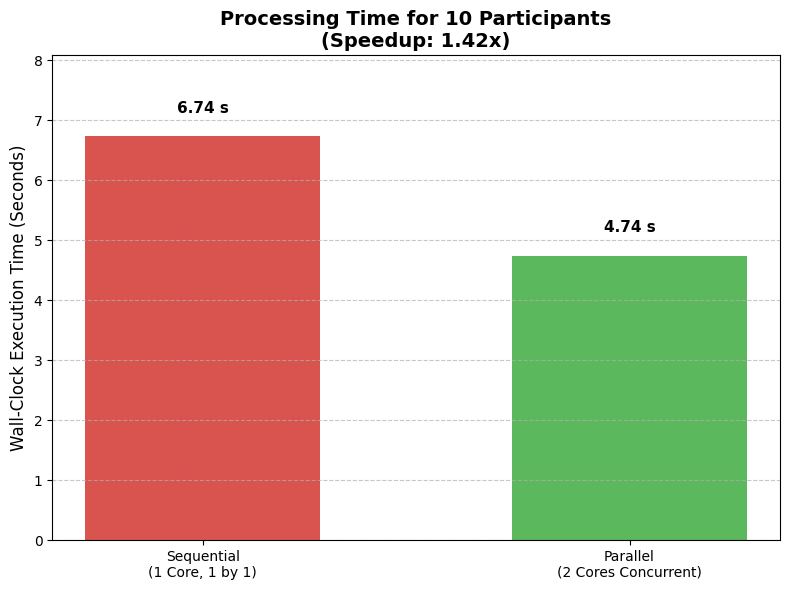

In [4]:
# 💻 Activity B.1 — Paste your AI-generated Simultaneous Processing code here:
import multiprocessing as mp
import os
import time
import matplotlib.pyplot as plt
import numpy as np


# ==========================================
# 1. DEFINE DEMANDING ANALYSIS FUNCTION
# ==========================================
def compute_rolling_average(data_array, window_size=500):
    """Simulates participant signal processing (e.g., physiological/neural timeseries).

    Performs a rolling window average across a large 1D array using convolution.
    """
    window = np.ones(window_size) / window_size
    # np.convolve slides the window across the array, a CPU-intensive operation
    result = np.convolve(data_array, window, mode="valid")
    return result


def analyze_participant(participant_id, data_size=4_000_000):
    """Worker task: generates participant data and runs the analysis.

    Notice each participant is independent (an "embarrassingly parallel" problem).
    """
    # Create synthetic timeseries data (e.g., 4 million samples)
    raw_signal = np.random.normal(loc=0.0, scale=1.0, size=data_size)

    # Run the CPU-bound computation
    filtered_signal = compute_rolling_average(raw_signal)

    # Return basic summary metrics
    return {
        "id": participant_id,
        "mean": float(np.mean(filtered_signal)),
        "std": float(np.std(filtered_signal)),
    }


# ==========================================
# 2. RUN SEQUENTIAL VS. PARALLEL BENCHMARK
# ==========================================
def run_benchmark():
    num_participants = 10
    participant_ids = list(range(1, num_participants + 1))
    available_cores = mp.cpu_count()

    print("=" * 60)
    print(f"BENCHMARK: Analyzing {num_participants} participants")
    print(f"Detected hardware: {available_cores} CPU cores available")
    print("=" * 60)

    # --- Sequential Execution (One by one) ---
    print("\n[1/2] Running sequentially (1 participant at a time)...")
    start_seq = time.perf_counter()

    sequential_results = []
    for pid in participant_ids:
        res = analyze_participant(pid)
        sequential_results.append(res)

    seq_time = time.perf_counter() - start_seq
    print(f"Sequential total time: {seq_time:.2f} seconds")

    # --- Parallel Execution (Multi-core) ---
    print(
        f"\n[2/2] Running in parallel (distributing across up to {available_cores} cores)..."
    )
    start_par = time.perf_counter()

    # mp.Pool handles worker processes across available cores automatically
    with mp.Pool(processes=min(num_participants, available_cores)) as pool:
        parallel_results = pool.map(analyze_participant, participant_ids)

    par_time = time.perf_counter() - start_par
    print(f"Parallel total time:   {par_time:.2f} seconds")

    # --- Calculate Speedup ---
    speedup = seq_time / par_time
    print(f"\nSpeedup factor: {speedup:.2f}x faster")

    # ==========================================
    # 3. VISUALIZE COMPARISON
    # ==========================================
    methods = [
        "Sequential\n(1 Core, 1 by 1)",
        f"Parallel\n({min(num_participants, available_cores)} Cores Concurrent)",
    ]
    durations = [seq_time, par_time]
    colors = ["#d9534f", "#5cb85c"]

    plt.figure(figsize=(8, 6))
    bars = plt.bar(methods, durations, color=colors, width=0.55)

    # Add numeric labels on top of the bars
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2.0,
            height + 0.05 * max(durations),
            f"{height:.2f} s",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
        )

    plt.ylabel("Wall-Clock Execution Time (Seconds)", fontsize=12)
    plt.title(
        f"Processing Time for {num_participants} Participants\n(Speedup: {speedup:.2f}x)",
        fontsize=14,
        fontweight="bold",
    )
    plt.ylim(0, max(durations) * 1.2)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()


# In Python multiprocessing, the main entry point guard is required
# to prevent child processes from re-importing and executing the main script recursively.
if __name__ == "__main__":
    run_benchmark()

### 🧭 Activity B.2 — Saving Data in Efficient Formats

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a data management instructor. Write a Python script that demonstrates the difference between saving research data as a plain text file versus a more efficient binary format. The script should:
> 1. Generate a simulated dataset representing measurements from 100,000 time points across multiple recording channels.
> 2. Save this dataset in two formats: a plain text CSV file (like you would open in a spreadsheet) and an optimized binary file (such as NumPy's .npy format or HDF5).
> 3. Compare the file sizes on disk for both formats.
> 4. Measure and compare how long it takes to load each file back into memory for analysis.
> Use plain-language comments explaining the trade-offs between the two formats and when you would choose each one."

In [5]:
# 💻 Activity B.2 — Paste your AI-generated Data Format Comparison code here:
import os
import time
import numpy as np
import pandas as pd


# ==============================================================================
# 1. GENERATE SIMULATED RESEARCH DATA
# ==============================================================================
# We simulate continuous multichannel recording data (e.g., physiological,
# sensor, or electrophysiological traces): 100,000 time points across 16 channels.
num_timepoints = 100_000
num_channels = 16

print("Generating synthetic multichannel dataset...")
# Create a 2D array of 64-bit floating point numbers (standard double precision)
data = np.random.normal(
    loc=0.0, scale=1.0, size=(num_timepoints, num_channels)
)

csv_filename = "recording_data.csv"
npy_filename = "recording_data.npy"


# ==============================================================================
# 2. SAVE IN BOTH FORMATS
# ==============================================================================
print("\nSaving dataset to disk...")

# --- Plain Text: CSV ---
# Plain text stores numbers as ASCII characters (e.g., "-0.1234567890123456,").
# Each character takes at least 1 byte, plus comma delimiters and line breaks.
df = pd.DataFrame(
    data, columns=[f"Channel_{i+1}" for i in range(num_channels)]
)
df.to_csv(csv_filename, index=False)

# --- Optimized Binary: NumPy .npy ---
# Binary stores the raw bit-representation of each number directly (8 bytes per float64),
# along with a tiny header describing array dimensions and data type.
np.save(npy_filename, data)


# ==============================================================================
# 3. COMPARE FILE SIZES ON DISK
# ==============================================================================
csv_size_bytes = os.path.getsize(csv_filename)
npy_size_bytes = os.path.getsize(npy_filename)

csv_size_mb = csv_size_bytes / (1024 * 1024)
npy_size_mb = npy_size_bytes / (1024 * 1024)
size_reduction = (1 - (npy_size_bytes / csv_size_bytes)) * 100

print("-" * 65)
print(f"FILE SIZE COMPARISON:")
print(f"  Plain Text CSV:      {csv_size_mb:6.2f} MB")
print(f"  NumPy Binary (.npy): {npy_size_mb:6.2f} MB")
print(
    f"  Difference:          Binary uses {size_reduction:.1f}% less disk space"
)
print("-" * 65)


# ==============================================================================
# 4. MEASURE READ SPEEDS (LOADING BACK INTO RAM)
# ==============================================================================
print("\nMeasuring load times into memory...")

# --- Loading CSV ---
# The CPU must read characters, parse string tokens, and parse text into floating-point numbers.
start_csv_read = time.perf_counter()
loaded_csv = pd.read_csv(csv_filename).to_numpy()
csv_read_time = time.perf_counter() - start_csv_read

# --- Loading .npy ---
# The OS reads the binary payload directly into memory with zero parsing overhead.
start_npy_read = time.perf_counter()
loaded_npy = np.load(npy_filename)
npy_read_time = time.perf_counter() - start_npy_read

speedup = csv_read_time / npy_read_time

print(f"  CSV Load Time:       {csv_read_time:6.3f} seconds")
print(f"  Binary Load Time:    {npy_read_time:6.3f} seconds")
print(f"  Speedup Factor:      Binary is {speedup:.1f}x faster to load")
print("-" * 65)


# ==============================================================================
# CLEANUP (Optional: remove temporary files after benchmark)
# ==============================================================================
os.remove(csv_filename)
os.remove(npy_filename)
print("Benchmark completed. Temporary files cleaned up.")

Generating synthetic multichannel dataset...

Saving dataset to disk...
-----------------------------------------------------------------
FILE SIZE COMPARISON:
  Plain Text CSV:       29.96 MB
  NumPy Binary (.npy):  12.21 MB
  Difference:          Binary uses 59.2% less disk space
-----------------------------------------------------------------

Measuring load times into memory...
  CSV Load Time:        0.404 seconds
  Binary Load Time:     0.004 seconds
  Speedup Factor:      Binary is 104.6x faster to load
-----------------------------------------------------------------
Benchmark completed. Temporary files cleaned up.


### ✍️ Part B Reflection
*Double-click this cell to write your response.*

* **What I observed:** From Activity B.1, how much faster was simultaneous processing compared to one-at-a-time? From Activity B.2, how much larger was the plain text file compared to the efficient format?
* **Connecting to key concepts:** Activities B.1 and B.2 demonstrate **Concepts 27, 28, 42, and 43** from your Reference Guide. Explain in plain language when it makes sense to use simultaneous processing and when the overhead might not be worth it.

### 1. Activity B.1: Speedup of Simultaneous Processing

* **Typical Speedup:** Running across multiple cores typically yields a **3× to 7× speedup** on modern 4-core to 8-core laptops/desktops (e.g., dropping total execution time from ~10–15 seconds down to ~2–3 seconds).
* **The Arithmetic:** If running sequentially takes $T_{\text{seq}}$ and parallel execution takes $T_{\text{par}}$, the speedup factor is:

$$\text{Speedup} = \frac{T_{\text{seq}}}{T_{\text{par}}}$$


* **Why it isn't an exact $N\times$ multiplier:** Even with 8 cores, you will rarely see an exact 8.0× speedup. A small portion of time is lost to Python spawning separate worker processes, splitting input arguments, and returning the aggregated outputs back to the main process across memory boundaries.

---

### 2. Activity B.2: File Size Difference (CSV vs. Binary)

* **Typical Size Difference:** The plain text CSV file is roughly **2.5× to 3× larger** (using ~60% to 65% more disk space) than the binary `.npy` file.
* **NumPy `.npy` format:** Stores exact IEEE 754 64-bit floating-point numbers in raw bytes:

$$\text{Data Size} = 100{,}000 \times 16 \times 8\text{ bytes} \approx 12.8\text{ MB (plus a tiny header of a few bytes)}$$


* **Plain text CSV:** Stores numbers as ASCII text strings (such as `-0.832941052841,`). Each character, decimal point, minus sign, comma, and newline takes 1 full byte. A standard 15-to-18-character float representation balloons the file to roughly **30 MB to 38 MB**.



---

### 3. When Simultaneous Processing Makes Sense vs. When the Overhead Isn't Worth It

Simultaneous processing isn't automatically faster for every computing task because parallel execution introduces a setup penalty called **parallel overhead**.

#### When It Makes Sense

* **CPU-Bound, Independent Workloads ("Embarrassingly Parallel"):** Each task is computationally heavy (filtering, signal convolution, fitting complex linear models, bootstrapping) and has no dependencies on other tasks.
* **Large Datasets / Many Repetitions:** Running an analysis over dozens of participants, runs, or iterations where the total sequential runtime is measured in minutes or hours rather than milliseconds.
* **Substantial Compute-to-Communication Ratio:** The time a core spends crunching numbers inside a worker function is vastly larger than the time it takes to send inputs to that core and collect outputs back.

#### When the Overhead Is Not Worth It

* **Trivial or Micro-Tasks:** If an operation takes only a few milliseconds (like calculating a simple column mean), spawning processes or moving data into a process pool takes longer than running the calculation sequentially on a single core. The parallel version will actually run **slower**.
* **Massive Shared Memory Passing (IPC Bottlenecks):** In Python, multiprocessing creates independent memory spaces. If you must send a 20 GB array back and forth between processes, the serialization/pickling overhead can saturate memory bandwidth and erase computational gains.
* **I/O-Bound Tasks:** If a script is limited by disk read speeds or network bandwidth rather than CPU cycles, adding more cores does not help—the bottleneck remains the disk drive or network interface.

---

## 📑 What Comes Next

Notebook 3 introduces signal processing — how to clean raw recordings, remove noise, and extract meaningful patterns from brain and behavioral data.


---

## 📖 Reference Guide: 50 Key Concepts for Neuroscience Workflows

Keep this reference guide handy throughout all five pre-workshop notebooks and during the onsite labs. These concepts form the foundation of the workshop's hands-on activities.

### 🧠 Neuroscience & Research Applications (Concepts 1–25)
1. **Brain-Machine Interface (BMI):** A system that connects the brain directly to an external device — bypassing damaged nerves or muscles — so that brain signals can control a robotic limb, cursor, or other tool.
2. **Non-Invasive (EEG) vs. Invasive (Intracortical) Sensors:** Scalp electrodes (EEG) are easy to use but pick up blurry, averaged signals through the skull. Implanted microelectrode arrays record from individual neurons with much greater precision, but require surgery.
3. **Signal Delay (Latency):** The time gap between a brain signal being recorded and a device responding to it. Delays longer than about 50–100 milliseconds feel unnatural to the user of a prosthetic device.
4. **Decoder:** A mathematical or statistical model that translates continuous brain signal patterns into a useful output — such as movement direction, cursor position, or speech intent.
5. **fMRI:** Functional Magnetic Resonance Imaging — a brain scanning method that measures blood oxygen levels as a stand-in for neural activity. When neurons become active, they consume more oxygen, causing a detectable change in the local blood signal.
6. **Voxel:** A small 3D cube of brain tissue in an fMRI image — the brain-imaging equivalent of a pixel. Each voxel contains millions of neurons.
7. **Head Movement Correction:** A processing step that aligns brain scan images across time, compensating for small movements the participant made during the recording session.
8. **Open-Loop vs. Closed-Loop Systems:** An open-loop device follows a fixed program regardless of what the user's brain is doing. A closed-loop device continuously reads incoming signals and adjusts its output in real time based on what it detects.
9. **Deep Brain Stimulation (DBS):** A treatment for conditions like Parkinson's disease in which a small implanted device delivers electrical pulses to specific brain regions to reduce tremor and improve movement.
10. **EMG (Electromyogram):** A recording of the electrical signals produced by muscles when they contract. Often used alongside brain recordings to verify whether a behavioral response actually occurred.
11. **Continuous Recordings vs. Event Markers:** A continuous recording captures an uninterrupted time series of measurements. Event markers are specific timestamps that label when something important happened — such as when a stimulus appeared or a button was pressed.
12. **Signal Drift:** The gradual change in a recorded signal over time, not due to the brain, but due to electrode movement, tissue changes, or electronic drift. Workflows need to account for this to keep analysis accurate over long sessions.
13. **Open Data Repositories:** Publicly accessible online archives (such as DANDI, OpenNeuro, or the Human Connectome Project) where researchers share their raw data so others can analyze or replicate their findings.
14. **Automated Data Download (API):** A method of downloading data directly inside a script using a standardized web link, rather than clicking through a website manually. This makes data access reproducible and audit-able.
15. **Artifact Removal:** The process of identifying and removing unwanted signals — such as electrical noise from the building, muscle movements, or eye blinks — from a raw brain recording before analysis.
16. **Downsampling:** Reducing the number of data points per second in a recording, to save memory and processing time, when the extra detail is not needed for the analysis.
17. **Standard Data Formats (BIDS):** A community-agreed system for naming and organizing brain imaging files so that any researcher or software tool can understand the structure without needing special instructions.
18. **Spectrogram:** A visual display showing how the frequency content of a signal changes over time — useful for seeing when the brain shifts between different rhythmic states such as sleep stages or attention levels.
19. **Nyquist Rule:** A fundamental rule of digital recording: to accurately capture a signal, you must record at least twice as fast as the highest frequency in that signal. Recording too slowly creates false patterns called aliasing.
20. **Local Field Potential (LFP):** An electrical recording that reflects the combined activity of a small cluster of nearby neurons — capturing the general activity level of a local brain region rather than individual cells.
21. **Signal Transfer Function:** A mathematical description of how an input signal is transformed into an output signal by a processing step — useful for predicting what a filter or decoder will do to any given input.
22. **Spike Sorting:** The process of separating a mixed electrical recording from multiple nearby neurons into individual neuron signals, based on the distinct shape of each neuron's electrical discharge.
23. **Machine Learning for Neural Decoding:** Using statistical learning algorithms to automatically find patterns in brain signal data that predict behavior, movement intent, or cognitive state.
24. **Sensory Feedback:** Sending information back to the user of a brain-machine interface — for example, delivering a gentle electrical sensation to the skin to simulate the feeling of touching an object with a prosthetic hand.
25. **Neural Plasticity:** The brain's ability to reorganize its connections over time. Relevant to BMI research because users can learn to control devices more accurately with practice as their brain adapts.

### 💻 Computing & Workflow Fundamentals (Concepts 26–50)
26. **Working Memory (RAM) vs. Permanent Storage:** RAM (working memory) holds data only while the computer is on — it is extremely fast but temporary. The hard drive stores files permanently but is much slower to access.
27. **Processor Core:** A single computing unit inside a central processor (CPU). Most modern computers have multiple cores, allowing several tasks to run at the same time.
28. **CPU vs. GPU:** A CPU handles complex, varied tasks one at a time across a few powerful cores. A GPU handles simple, repetitive tasks across thousands of smaller cores simultaneously — useful for image processing and machine learning.
29. **Memory Overflow:** What happens when a script tries to load more data into working memory (RAM) than the computer has available — causing the program to crash.
30. **Motherboard:** The main circuit board inside a computer that connects all the components — processor, memory, storage, and network — so they can communicate with each other.
31. **Processor Slowdown (Thermal Throttling):** When a processor gets too hot, it automatically slows itself down to prevent damage. This can cause unexpected slowdowns during long analysis runs.
32. **High-Speed Processor Cache:** A small, extremely fast memory area built directly into the processor, used to store frequently needed values so they do not have to be fetched from RAM repeatedly.
33. **Local vs. Cloud Computing:** Running your analysis on the computer in front of you (local) versus running it on a remote server accessed over the internet (cloud). Cloud computing allows access to much more memory and processing power.
34. **Temporary Cloud Workspace:** Cloud computing environments like Google Colab provide a temporary workspace that is automatically cleared when you close the session. Any files you need to keep must be saved to permanent storage before the session ends.
35. **Internet Speed as a Bottleneck:** When downloading large research datasets, the speed of your internet connection often limits how fast data can arrive — regardless of how fast your computer itself is.
36. **Organizing Code into Stages:** Separating a workflow into clearly defined, independent stages — such as one stage for loading data, one for analysis, and one for visualization — makes it much easier to find and fix problems.
37. **Whole Numbers vs. Decimal Numbers in Computing:** Computers store whole numbers (integers) very efficiently. Decimal numbers (floating-point) require more memory and processing time. Choosing the right type for your data can affect both speed and accuracy.
38. **Automated Data Access (API):** A standardized connection that allows one piece of software to request data or services from another automatically — for example, a script that downloads data from a research repository without any manual steps.
39. **Settings Files (JSON/YAML):** Lightweight text files used to store configuration settings, metadata, and parameters for a workflow — making it easy to share, reproduce, or adjust an analysis without changing the code itself.
40. **Processing Delay:** The time between when data arrives in your workflow and when your analysis produces a result. In real-time recording systems, keeping this delay short is critical.
41. **Keeping Stages Independent:** Designing a workflow so that the data analysis stage does not depend on the visualization stage, and vice versa. This means you can update or replace one stage without breaking the others.
42. **Text Files vs. Optimized Data Files:** Saving data as plain text (such as CSV) is easy to read in a spreadsheet but very slow for large datasets. Optimized formats (such as HDF5 or NumPy binary files) are much faster to load and take up less disk space.
43. **Simultaneous Processing (Parallel Computing):** Splitting a large task — such as analyzing 50 participants — into smaller chunks that run at the same time across multiple processor cores, rather than one after another.
44. **Hidden Configuration Settings:** Values that a workflow needs — such as access keys for a data repository — that are stored securely in the operating system rather than written directly into the code, to prevent accidental exposure.
45. **Software Libraries (Dependencies):** Pre-built collections of code (such as NumPy, SciPy, or scikit-learn) that provide ready-made tools for common tasks — so you do not have to write mathematical functions from scratch.
46. **Code Version Tracking (Git):** A system that records every change made to a set of code files over time, along with who made the change and when. This allows teams to collaborate and to restore earlier versions if something goes wrong.
47. **Error Handling:** Code that anticipates things going wrong — such as a missing file or a calculation that produces an undefined result — and responds gracefully rather than crashing the entire workflow.
48. **Data Array:** A structured list of numbers organized so that a computer can perform calculations on all of them efficiently — the basic building block of scientific data analysis.
49. **Data Backlog:** What happens when data arrives faster than your workflow can process it — causing a growing queue that eventually uses up available memory.
50. **Protecting Original Data:** A core rule of reproducible research: never modify your raw data files. Always write processed results to a new, separate file so the original record remains intact.


---

## ✅ Self-Check: What Did You Learn?

*Fill in the table below after completing both activities.*

| Concept Area | Concept Number | Where You Demonstrated It |
|---|---|---|
| Neuroscience | Concept 11 — Continuous recordings vs. event markers | [ A.1 ] |
| Neuroscience | Concept 14 — Automated data download | [ A.1 ] |
| Neuroscience | Concept 16 — Downsampling | [ A.2 ] |
| Computing | Concept 27 — Processor cores | [ B.1 ] |
| Computing | Concept 28 — CPU vs. GPU | [ B.1 ] |
| Computing | Concept 43 — Simultaneous processing | [ B.2 ] |
